# Segmentar los viajes de un taxi sin saber de antemano qué tipos de viaje existen

**Herramientas:** MiniBatch K-Means (el modelo que se lleva), Gaussian Mixture y DBSCAN (contrincantes).
**Datos:** viajes de taxímetro de Nueva York registrados por la *NYC TLC* (*Yellow Taxi*), enero de 2024: **2.964.624 viajes reales**.

La pregunta de partida no trae la respuesta de serie: *¿qué tipos de viaje existen en una ciudad si nadie nos ha dado la lista?* El notebook recorre el camino entero: limpiar los datos, decidir con cuántos grupos se va a trabajar, entrenar, medir con las tres métricas internas que pide el enunciado, dibujar los grupos y, sobre todo, **contar qué hay dentro de cada uno**.

**Índice**

1. Entorno y descarga del dataset
2. La pregunta de negocio y el criterio para elegir los datos
3. Primera mirada al dataset
4. Limpieza: nulos, duplicados, imposibles y extremos
5. Las variables que entran al modelo y su estandarización
6. ¿Cuántos grupos? El número no se inventa
7. MiniBatch K-Means, el modelo que se lleva
8. GMM y DBSCAN como contrincantes
9. Las tres métricas: silueta, Davies-Bouldin y Calinski-Harabasz
10. Dibujar los grupos
11. Qué contiene cada grupo
12. Límites, riesgos y veredicto


## 1. Entorno y datos de partida

La primera celda instala lo que falte (en Colab casi nada viene preinstalado) y la segunda baja el archivo Parquet desde el CDN oficial de la *NYC Taxi & Limousine Commission*. **No hace falta cuenta, ni API key, ni token**: es un archivo público. Si el Parquet ya está en `data/`, no se vuelve a descargar.


In [1]:
# Instalación de dependencias: solo se instala lo que falte (en Colab casi todo viene preinstalado).
import sys, subprocess, importlib.util

EN_COLAB = "google.colab" in sys.modules
print("¿Ejecutando en Google Colab?", EN_COLAB)

requeridos = {"pandas": "pandas", "pyarrow": "pyarrow", "numpy": "numpy", "sklearn": "scikit-learn",
              "matplotlib": "matplotlib", "seaborn": "seaborn"}
faltantes = [pip for mod, pip in requeridos.items() if importlib.util.find_spec(mod) is None]
if faltantes:
    print("Instalando:", faltantes)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltantes], check=True)
else:
    print("Todas las dependencias están instaladas.")

Todas las dependencias están instaladas.


In [ ]:
import os, time, urllib.request

URL_DATASET = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
RUTA_DATOS = os.path.join("data", "yellow_tripdata_2024-01.parquet")
os.makedirs("data", exist_ok=True)

if not os.path.exists(RUTA_DATOS):
    print("Descargando dataset (~50 MB)...")
    t0 = time.time()
    urllib.request.urlretrieve(URL_DATASET, RUTA_DATOS)
    print(f"Descarga completada en {time.time()-t0:.1f} s")
else:
    print("El dataset ya existe localmente:", RUTA_DATOS)
print(f"Tamaño del archivo: {os.path.getsize(RUTA_DATOS)/1e6:.1f} MB")

El dataset ya existe localmente: data/yellow_tripdata_2024-01.parquet
Tamaño del archivo: 50.0 MB


In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import MiniBatchKMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

SEMILLA = 42                     # reproducibilidad
np.random.seed(SEMILLA)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

## 2. La pregunta de negocio y el criterio para elegir los datos

### El problema

Una empresa de movilidad (o la propia autoridad de transporte) quiere **descubrir qué tipos de viaje hay** en su flota sin que nadie le haya entregado una lista de categorías. Las preguntas que se quieren responder:

- ¿Qué perfiles de viaje conviven en la ciudad (trayectos cortos urbanos, viajes al aeropuerto, desplazamientos nocturnos, salidas de fin de semana...)?
- ¿En qué se diferencian esos perfiles en distancia, duración, velocidad, tarifa y propina?
- ¿ cuáles concentran el valor (tarifa alta, buena propina) y cuáles son poco eficientes (mucha distancia a muy poca velocidad por congestión)?

Con esas respuestas se pueden diseñar tarifas dinámicas, repartir la flota por franja horaria, planear campañas de fidelización y anticipar la congestión.

### Por qué el dataset de los taxis de Nueva York

| Criterio | NYC Yellow Taxi (enero de 2024) |
|---|---|
| Real | Sí: registros oficiales de taxímetros reportados a la NYC TLC |
| Volumen | 2.964.624 viajes, muy por encima de los 100.000 exigidos |
| Acceso | Descarga directa en Parquet desde una CDN pública, **sin autenticación** |
| Riqueza | Variables numéricas (distancia, tarifa, propina, peajes), temporales (hora, día) y categóricas (tipo de pago, tarifa, vendor) |
| Eficiencia | Parquet columnar: carga en menos de un segundo, ideal para Colab |

Frente a *Online Retail II* (UCI), que al agregar por cliente (RFM) se queda en unos 5.900 registros, el dataset de taxis permite **segmentar directamente más de 100.000 registros** y obliga a trabajar con algoritmos escalables, que es justo de lo que se trata.

### Las variables que se van a usar

| Variable derivada | De dónde sale | Qué representa |
|---|---|---|
| `log_distancia` | `trip_distance` | Distancia del viaje (millas), en escala logarítmica |
| `log_duracion` | `dropoff − pickup` | Duración (minutos), en escala logarítmica |
| `velocidad_mph` | distancia ÷ duración | Velocidad media, a modo de indicador de congestión |
| `log_tarifa` | `fare_amount` | Tarifa base del taxímetro (USD), en escala logarítmica |
| `pct_propina` | `tip_amount ÷ fare_amount` | Generosidad de la propina |
| `hora_sin`, `hora_cos` | hora de recogida | Codificación **cíclica** de la hora (las 23 h y las 0 h quedan cerca) |
| `fin_semana` | día de la semana | 1 si es sábado o domingo |
| `aeropuerto` | `Airport_fee`, `RatecodeID` | 1 si el viaje toca JFK, LaGuardia o Newark |

> **Punto clave:** no existe ninguna variable objetivo en este trabajo. Campos como `payment_type` o `RatecodeID` se usan únicamente para **filtrar o construir variables descriptivas**, nunca como etiquetas que el modelo tenga que adivinar.


## 3. Primera mirada al dataset


In [4]:
t0 = time.time()
df_raw = pd.read_parquet(RUTA_DATOS)
print(f"Carga en {time.time()-t0:.1f} s")
print(f"Registros: {df_raw.shape[0]:,} | Columnas: {df_raw.shape[1]}")
df_raw.head()

Carga en 0.4 s
Registros: 2,964,624 | Columnas: 19


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.000,1.720,1.000,N,186,79,2,17.700,1.000,0.500,0.000,0.000,1.000,22.700,2.500,0.000
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.000,1.800,1.000,N,140,236,1,10.000,3.500,0.500,3.750,0.000,1.000,18.750,2.500,0.000
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.000,4.700,1.000,N,236,79,1,23.300,3.500,0.500,3.000,0.000,1.000,31.300,2.500,0.000
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.000,1.400,1.000,N,79,211,1,10.000,3.500,0.500,2.000,0.000,1.000,17.000,2.500,0.000
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.000,0.800,1.000,N,211,148,1,7.900,3.500,0.500,3.200,0.000,1.000,16.100,2.500,0.000


In [5]:
df_raw.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 2964624 entries, 0 to 2964623
Data columns (total 19 columns):
 #   Column                 Non-Null Count    Dtype         
---  ------                 --------------    -----         
 0   VendorID               2964624 non-null  int32         
 1   tpep_pickup_datetime   2964624 non-null  datetime64[us]
 2   tpep_dropoff_datetime  2964624 non-null  datetime64[us]
 3   passenger_count        2824462 non-null  float64       
 4   trip_distance          2964624 non-null  float64       
 5   RatecodeID             2824462 non-null  float64       
 6   store_and_fwd_flag     2824462 non-null  str           
 7   PULocationID           2964624 non-null  int32         
 8   DOLocationID           2964624 non-null  int32         
 9   payment_type           2964624 non-null  int64         
 10  fare_amount            2964624 non-null  float64       
 11  extra                  2964624 non-null  float64       
 12  mta_tax                2964624 non-null

In [6]:
df_raw.describe().T

,count,mean,min,25%,50%,75%,max,std
VendorID,"2,964,624.000",1.754,1.000,2.000,2.000,2.000,6.000,0.433
tpep_pickup_datetime,2964624,2024-01-17 00:46:36.431092,2002-12-31 22:59:39,2024-01-09 15:59:19.750000,2024-01-17 10:45:37.500000,2024-01-24 18:23:52.250000,2024-02-01 00:01:15,NaN
tpep_dropoff_datetime,2964624,2024-01-17 01:02:13.208130,2002-12-31 23:05:41,2024-01-09 16:16:23,2024-01-17 11:03:51.500000,2024-01-24 18:40:29,2024-02-02 13:56:52,NaN
passenger_count,"2,824,462.000",1.339,0.000,1.000,1.000,1.000,9.000,0.850
trip_distance,"2,964,624.000",3.652,0.000,1.000,1.680,3.110,"312,722.300",225.463
RatecodeID,"2,824,462.000",2.069,1.000,1.000,1.000,1.000,99.000,9.823
PULocationID,"2,964,624.000",166.018,1.000,132.000,162.000,234.000,265.000,63.624
DOLocationID,"2,964,624.000",165.117,1.000,114.000,162.000,234.000,265.000,69.315
payment_type,"2,964,624.000",1.161,0.000,1.000,1.000,1.000,4.000,0.581
fare_amount,"2,964,624.000",18.175,-899.000,8.600,12.800,20.500,"5,000.000",18.950


**Observaciones iniciales del `describe()`:**
- Hay **valores imposibles**: tarifas negativas (hasta −899 USD), distancias de 312.722 millas, fechas de 2002 y viajes con 0 pasajeros. Son errores del taxímetro o ajustes/reembolsos.
- Las variables monetarias y de distancia son **muy asimétricas** (la media es mucho mayor que la mediana), por eso se aplicará transformación logarítmica.

In [7]:
# Nulos por columna
nulos = df_raw.isna().sum().to_frame("nulos")
nulos["porcentaje"] = 100 * nulos["nulos"] / len(df_raw)
nulos[nulos["nulos"] > 0]

,nulos,porcentaje
passenger_count,140162,4.728
RatecodeID,140162,4.728
store_and_fwd_flag,140162,4.728
congestion_surcharge,140162,4.728
Airport_fee,140162,4.728


In [8]:
# ¿Los nulos aparecen en las mismas filas? ¿Con qué tipo de pago?
filas_nulas = df_raw["passenger_count"].isna()
print("Filas con nulos simultáneos en las 5 columnas:",
      df_raw.loc[filas_nulas, ["RatecodeID","store_and_fwd_flag","congestion_surcharge","Airport_fee"]].isna().all(axis=1).sum())
print("\npayment_type de las filas con nulos:")
print(df_raw.loc[filas_nulas, "payment_type"].value_counts())

Filas con nulos simultáneos en las 5 columnas: 140162

payment_type de las filas con nulos:
payment_type
0    140162
Name: count, dtype: int64


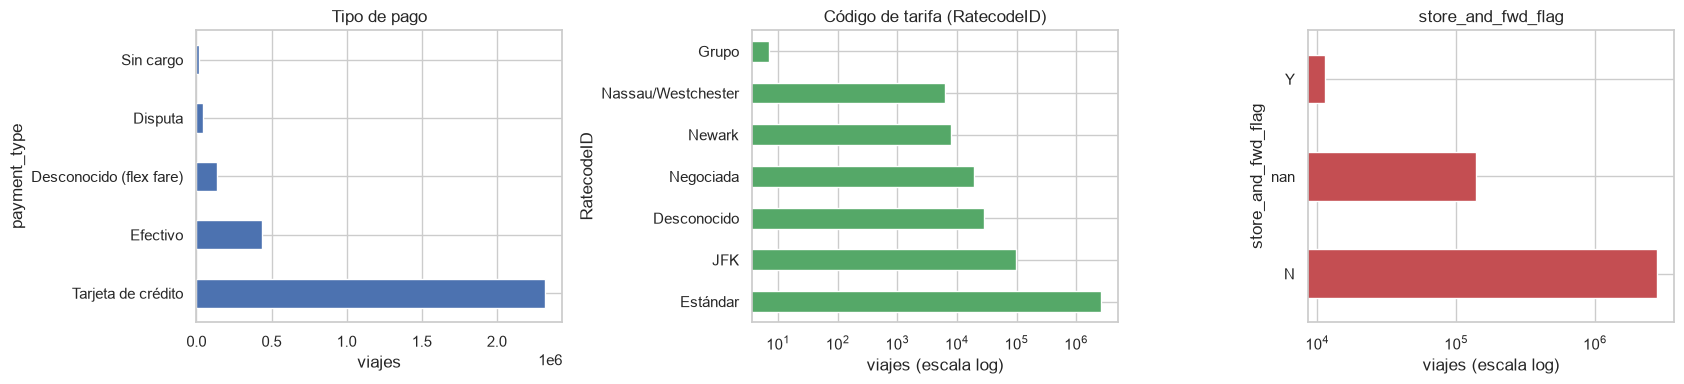

In [9]:
# Variables categóricas / códigos
DICC_PAGO = {0: "Desconocido (flex fare)", 1: "Tarjeta de crédito", 2: "Efectivo",
             3: "Sin cargo", 4: "Disputa", 5: "Desconocido", 6: "Viaje anulado"}
DICC_TARIFA = {1: "Estándar", 2: "JFK", 3: "Newark", 4: "Nassau/Westchester",
               5: "Negociada", 6: "Grupo", 99: "Desconocido"}

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
df_raw["payment_type"].map(DICC_PAGO).value_counts().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Tipo de pago"); axes[0].set_xlabel("viajes")
df_raw["RatecodeID"].map(DICC_TARIFA).value_counts().plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("Código de tarifa (RatecodeID)"); axes[1].set_xscale("log"); axes[1].set_xlabel("viajes (escala log)")
df_raw["store_and_fwd_flag"].value_counts(dropna=False).plot.barh(ax=axes[2], color="#C44E52")
axes[2].set_title("store_and_fwd_flag"); axes[2].set_xscale("log"); axes[2].set_xlabel("viajes (escala log)")
plt.tight_layout(); plt.show()

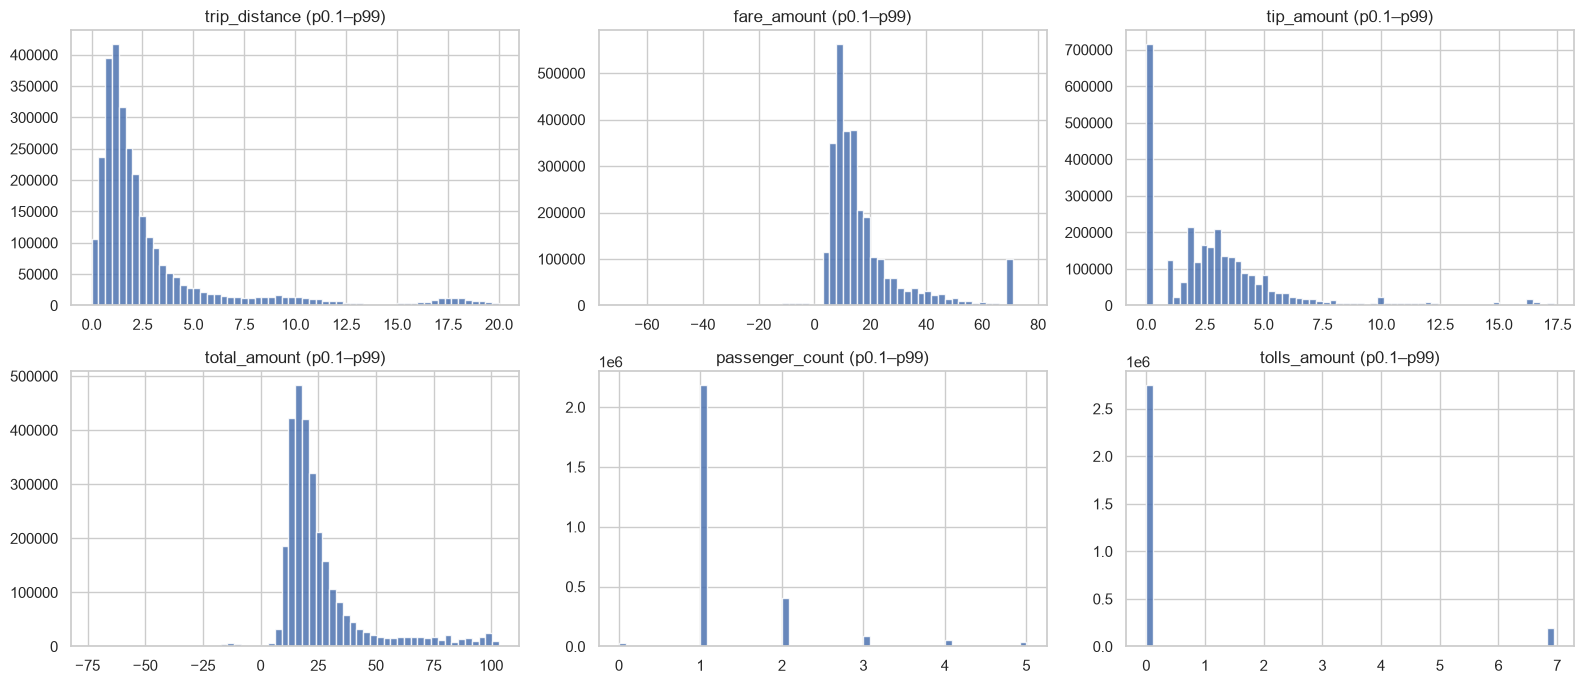

In [10]:
# Distribuciones crudas de variables numéricas clave (recortadas al percentil 99 solo para visualizar)
cols_num = ["trip_distance", "fare_amount", "tip_amount", "total_amount", "passenger_count", "tolls_amount"]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, c in zip(axes.ravel(), cols_num):
    s = df_raw[c].dropna()
    s = s[(s >= s.quantile(0.001)) & (s <= s.quantile(0.99))]
    ax.hist(s, bins=60, color="#4C72B0", alpha=.85)
    ax.set_title(f"{c} (p0.1–p99)")
plt.tight_layout(); plt.show()

**Tres cosas que ya se ven en los datos crudos**

- Las columnas `passenger_count`, `RatecodeID`, `store_and_fwd_flag`, `congestion_surcharge` y `Airport_fee` tienen un **4,73 % de nulos, siempre en las mismas 140.162 filas**. Esas filas tienen `payment_type = 0` (*flex fare*: viajes con tarifa pactada a través de una app, donde el taxímetro no registra estos campos). No es un faltante aleatorio, es **otro esquema de cobro**.
- Cerca del **78 % de los viajes se paga con tarjeta**. La propina solo se registra con tarjeta (en efectivo no se reporta), y ese dato condiciona el filtrado posterior.
- Las variables de distancia y de dinero están **muy asimétricas**, con colas larguísimas a la derecha. De ahí la necesidad de las transformaciones logarítmicas.


## 4. Limpiar antes de agrupar

### 4.1 Criterio de limpieza

| Problema | Decisión | Por qué |
|---|---|---|
| Nulos (4,73 %, `payment_type = 0`) | Eliminar las filas | Son viajes *flex fare* sin datos de tarifa ni de aeropuerto; imputarlos inventaría información que estructuralmente no existe |
| Pagos que no son con tarjeta | Filtrar `payment_type = 1` | La propina solo es fiable con tarjeta; meter efectivo crearía un falso grupo de "propina cero" |
| Duplicados | Eliminar duplicados exactos | Un registro repetido desplaza los centroides |
| Fechas fuera de enero de 2024 | Eliminar | Errores del reloj del taxímetro |
| Valores físicamente imposibles | Reglas de negocio (abajo) | Distancias, duraciones o tarifas que no pueden existir |
| Extremos que quedan | *Winsorización* entre p0,5 y p99,5 | K-Means es muy sensible a los extremos; recortar conserva el registro |


In [11]:
df = df_raw.copy()
n0 = len(df)
bitacora = []
def registrar(paso, df_actual):
    bitacora.append({"paso": paso, "registros": len(df_actual)})
registrar("Original", df)

# 1) Nulos: se eliminan (filas flex-fare, payment_type = 0)
df = df.dropna(subset=["passenger_count", "RatecodeID", "Airport_fee", "congestion_surcharge"])
registrar("Sin nulos", df)

# 2) Solo pagos con tarjeta (propina registrada de forma confiable)
df = df[df["payment_type"] == 1]
registrar("Solo tarjeta", df)

# 3) Duplicados exactos
dups = df.duplicated().sum()
print(f"Duplicados exactos encontrados: {dups:,}")
df = df.drop_duplicates()
registrar("Sin duplicados", df)

# 4) Fechas dentro de enero de 2024
df = df[(df["tpep_pickup_datetime"] >= "2024-01-01") & (df["tpep_pickup_datetime"] < "2024-02-01")]
registrar("Fechas válidas (ene-2024)", df)

Duplicados exactos encontrados: 0


In [12]:
# 5) Variables derivadas necesarias para las reglas de negocio
df["duracion_min"] = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
df["velocidad_mph"] = df["trip_distance"] / (df["duracion_min"] / 60)

reglas = (
    df["trip_distance"].between(0.1, 100) &        # al menos ~160 m y no más de 100 millas
    df["duracion_min"].between(1, 180) &           # entre 1 minuto y 3 horas
    df["velocidad_mph"].between(1, 80) &           # velocidades físicamente plausibles
    df["fare_amount"].between(3, 500) &            # tarifa mínima de bandera = 3 USD
    (df["tip_amount"] >= 0) &
    (df["RatecodeID"] != 99)                       # código de tarifa desconocido
)
df = df[reglas].copy()
registrar("Reglas de negocio", df)

pd.DataFrame(bitacora).assign(
    eliminados=lambda d: d["registros"].shift(1) - d["registros"],
    pct_restante=lambda d: 100 * d["registros"] / n0)

,paso,registros,eliminados,pct_restante
0,Original,2964624,NaN,100.000
1,Sin nulos,2824462,"140,162.000",95.272
2,Solo tarjeta,2319046,"505,416.000",78.224
3,Sin duplicados,2319046,0.000,78.224
4,Fechas válidas (ene-2024),2319036,10.000,78.224
5,Reglas de negocio,2265576,"53,460.000",76.420


### 4.2 Variables que no entran al modelo (y por qué)

- `payment_type`: se usa **solo para filtrar** (dejar los pagos con tarjeta). Nunca entra en la matriz de variables.
- `RatecodeID` + `Airport_fee`: se resumen en una variable **binaria `aeropuerto`** (1 si el viaje usa tarifa JFK/Newark o paga recargo de aeropuerto de LaGuardia/JFK). Codificar `RatecodeID` con *one-hot* generaría 6 columnas casi vacías que deformarían las distancias euclídeas.
- `store_and_fwd_flag` y `VendorID`: son metadatos técnicos del taxímetro, sin significado de negocio, así que se descartan.
- `PULocationID` / `DOLocationID`: unas 265 zonas categóricas. Un *one-hot* produciría 530 columnas dispersas, así que quedan **fuera del agrupamiento** y se usan solo para **interpretar** los grupos a posteriori.
- Hora del día: se codifica de forma **cíclica** (seno y coseno) para que las 23:00 y las 00:00 estén cerca entre sí.


In [13]:
df["hora"] = df["tpep_pickup_datetime"].dt.hour + df["tpep_pickup_datetime"].dt.minute / 60
# El accessor del dia de la semana cambio de nombre: .dt.dayofweek en pandas 2.x
# y .dt.day_of_week en pandas 3.x. Se usa el que exista en la version instalada.
_dt = df["tpep_pickup_datetime"].dt
df["dia_semana"] = _dt.day_of_week if hasattr(_dt, "day_of_week") else _dt.dayofweek  # 0 = lunes
df["fin_semana"] = (df["dia_semana"] >= 5).astype(int)
df["aeropuerto"] = ((df["Airport_fee"] > 0) | (df["RatecodeID"].isin([2, 3]))).astype(int)
df["pct_propina"] = df["tip_amount"] / df["fare_amount"]
df["hora_sin"] = np.sin(2 * np.pi * df["hora"] / 24)
df["hora_cos"] = np.cos(2 * np.pi * df["hora"] / 24)

print(f"Viajes de aeropuerto: {df['aeropuerto'].mean():.1%} | Fin de semana: {df['fin_semana'].mean():.1%}")

Viajes de aeropuerto: 9.1% | Fin de semana: 25.6%


### 4.3 Valores extremos: ni borrar ni dejar pasar

Los extremos se cuantifican con el criterio IQR (1,5 veces el rango intercuartílico) y se corrigen con **winsorización**: se recortan los valores por encima del percentil 99,5 y por debajo del 0,5. **No se eliminan filas**, porque después de aplicar las reglas de negocio los valores altos suelen ser viajes reales poco frecuentes (por ejemplo, Manhattan → Newark), que es justo el tipo de comportamiento que se quiere que un segmento recoja. Lo único que se busca es que su peso extremo no arrastre los centroides.


,Q1,Q3,outliers_IQR,pct,p0.5,p99.5,max
variable,,,,,,,
trip_distance,1.030,3.070,287597,12.694,0.300,21.440,88.400
duracion_min,7.250,18.417,124519,5.496,1.867,62.933,176.483
velocidad_mph,7.447,13.021,190871,8.425,2.888,39.707,77.818
fare_amount,8.600,19.800,228457,10.084,4.400,86.700,474.800
pct_propina,0.211,0.311,168036,7.417,0.000,0.618,23.488


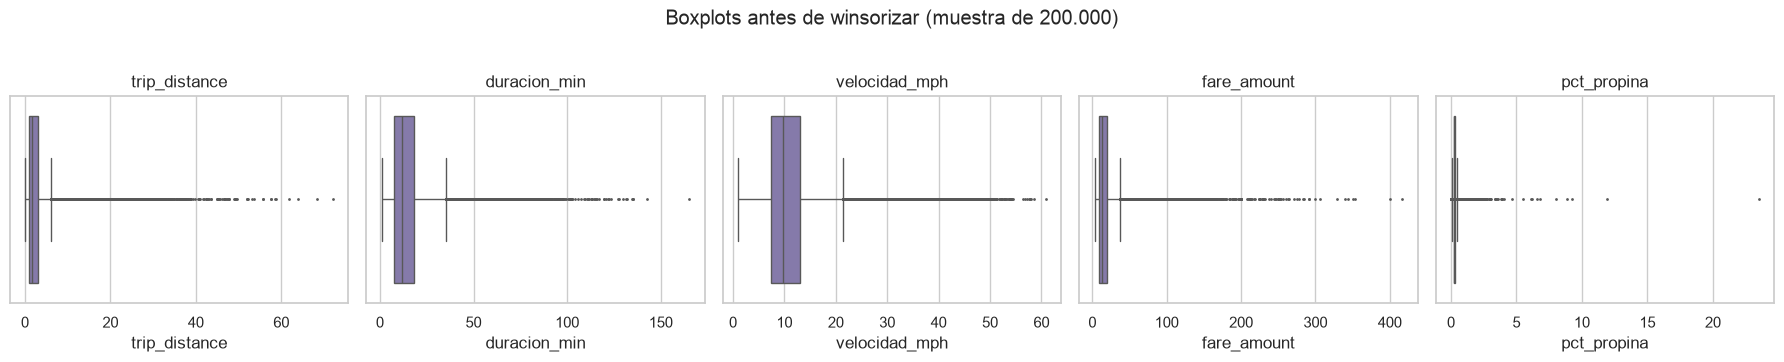

In [14]:
cols_outliers = ["trip_distance", "duracion_min", "velocidad_mph", "fare_amount", "pct_propina"]
resumen = []
for c in cols_outliers:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n_out = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    resumen.append({"variable": c, "Q1": q1, "Q3": q3, "outliers_IQR": n_out, "pct": 100*n_out/len(df),
                    "p0.5": df[c].quantile(.005), "p99.5": df[c].quantile(.995), "max": df[c].max()})
display(pd.DataFrame(resumen).set_index("variable"))

fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, c in zip(axes, cols_outliers):
    sns.boxplot(x=df[c].sample(200_000, random_state=SEMILLA), ax=ax, color="#8172B2", fliersize=1)
    ax.set_title(c)
plt.suptitle("Boxplots antes de winsorizar (muestra de 200.000)", y=1.03); plt.tight_layout(); plt.show()

In [15]:
# Winsorización p0.5 - p99.5
for c in cols_outliers:
    lo, hi = df[c].quantile([.005, .995])
    df[c] = df[c].clip(lo, hi)

# Transformaciones log para reducir asimetría
df["log_distancia"] = np.log1p(df["trip_distance"])
df["log_duracion"] = np.log1p(df["duracion_min"])
df["log_tarifa"] = np.log1p(df["fare_amount"])

print(f"Registros finales para clustering: {len(df):,}  ({len(df)/n0:.1%} del original)")

Registros finales para clustering: 2,265,576  (76.4% del original)


## 5. El espacio donde se buscan los grupos

Las variables viven en escalas muy distintas: la velocidad va en decenas, el porcentaje de propina en décimas y las binarias en 0 o 1. Como K-Means y el GMM trabajan con distancias euclídeas y covarianzas, **sin estandarizar dominaría la variable de mayor rango**. Se aplica `StandardScaler` (media 0 y desviación típica 1).


In [16]:
FEATURES = ["log_distancia", "log_duracion", "velocidad_mph", "log_tarifa",
            "pct_propina", "hora_sin", "hora_cos", "fin_semana", "aeropuerto"]

X = df[FEATURES].to_numpy(dtype=np.float64)
escalador = StandardScaler()
X_std = escalador.fit_transform(X)

print("Forma de la matriz:", X_std.shape)
pd.DataFrame(X_std, columns=FEATURES).describe().T[["mean", "std", "min", "max"]]

Forma de la matriz: (2265576, 9)


,mean,std,min,max
log_distancia,-0.000,1.000,-1.391,3.002
log_duracion,0.000,1.000,-2.402,2.586
velocidad_mph,-0.000,1.000,-1.323,4.360
log_tarifa,0.000,1.000,-1.694,2.859
pct_propina,0.000,1.000,-2.466,3.498
hora_sin,0.000,1.000,-1.075,2.162
hora_cos,0.000,1.000,-1.238,1.628
fin_semana,-0.000,1.000,-0.587,1.705
aeropuerto,0.000,1.000,-0.317,3.158


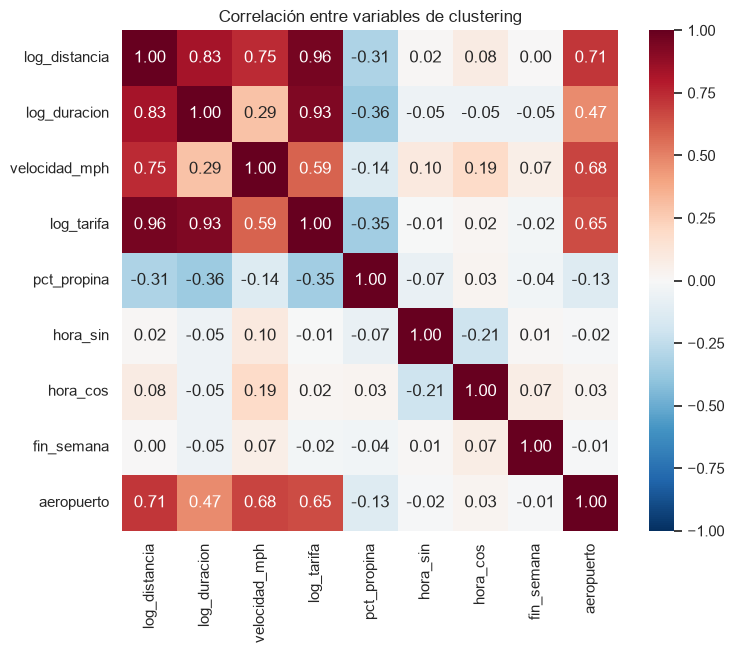

In [17]:
# Correlaciones entre variables (sobre una muestra)
idx_corr = np.random.RandomState(SEMILLA).choice(len(df), 200_000, replace=False)
plt.figure(figsize=(8, 6.5))
sns.heatmap(pd.DataFrame(X_std[idx_corr], columns=FEATURES).corr(), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlación entre variables de clustering"); plt.show()

Distancia, duración y tarifa están muy correlacionadas (la tarifa del taxímetro depende de ambas). Se mantienen porque la **velocidad** y el indicador de **aeropuerto** (tarifa plana en JFK) rompen parcialmente esa relación y aportan matices; la redundancia se discute en el apartado de limitaciones.

### Decisiones de muestreo

- **MiniBatch K-Means** se entrena con **todos** los registros: su coste es lineal y va por lotes.
- La **silueta** cuesta O(n²). Con dos millones de puntos harían falta unas 4·10¹² distancias, así que se calcula sobre una **muestra aleatoria de 30.000 puntos** (y 10.000 para la búsqueda de *k*). Con ese tamaño el error estándar del promedio es despreciable, y más adelante se mide la variabilidad con 5 muestras distintas para demostrarlo.
- El **GMM** con covarianza completa se entrena sobre una muestra de 300.000 registros y luego predice sobre todo el conjunto.
- **DBSCAN** es O(n²) en memoria en el peor caso, así que solo se ejecuta sobre la muestra de 30.000 puntos, a modo de comparación.


In [18]:
rng = np.random.RandomState(SEMILLA)
idx_eval = rng.choice(len(X_std), 30_000, replace=False)      # muestra común de evaluación
idx_k = rng.choice(len(X_std), 10_000, replace=False)         # muestra para la búsqueda de k
X_eval = X_std[idx_eval]
X_k = X_std[idx_k]

## 6. ¿Cuántos grupos? El número no se inventa

Se combinan dos criterios clásicos y otros dos de apoyo:

1. **Método del codo:** la inercia (suma de distancias al cuadrado al centroide) frente a *k*. Se busca el punto donde la mejora marginal se aplana.
2. **Silueta promedio:** mide cohesión frente a separación, y se mueve entre −1 y 1 (más alto es mejor).
3. **Davies-Bouldin** (más bajo es mejor) y **Calinski-Harabasz** (más alto es mejor), que sirven para desempatar.


In [19]:
rango_k = range(2, 11)
filas = []
t0 = time.time()
for k in rango_k:
    mbk = MiniBatchKMeans(n_clusters=k, batch_size=8192, n_init=5, max_iter=200, random_state=SEMILLA)
    mbk.fit(X_std)
    etq_k = mbk.predict(X_k)
    filas.append({"k": k, "inercia": mbk.inertia_,
                  "silhouette": silhouette_score(X_k, etq_k),
                  "davies_bouldin": davies_bouldin_score(X_k, etq_k),
                  "calinski_harabasz": calinski_harabasz_score(X_k, etq_k)})
print(f"Búsqueda de k completada en {time.time()-t0:.1f} s")
busqueda_k = pd.DataFrame(filas).set_index("k")
busqueda_k

Búsqueda de k completada en 108.7 s


,inercia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,"14,185,761.382",0.421,1.138,"4,472.183"
3,"12,049,816.608",0.204,1.685,"3,483.145"
4,"10,274,145.529",0.206,1.494,"3,299.506"
5,"9,038,434.112",0.227,1.337,"3,129.573"
6,"8,475,063.548",0.228,1.443,"2,812.815"
7,"8,268,421.972",0.212,1.604,"2,444.128"
8,"7,695,577.117",0.193,1.653,"2,358.260"
9,"7,336,922.689",0.203,1.554,"2,208.670"
10,"6,849,943.688",0.212,1.496,"2,180.829"


k sugerido por el codo: 5 | k con mayor silhouette: 2


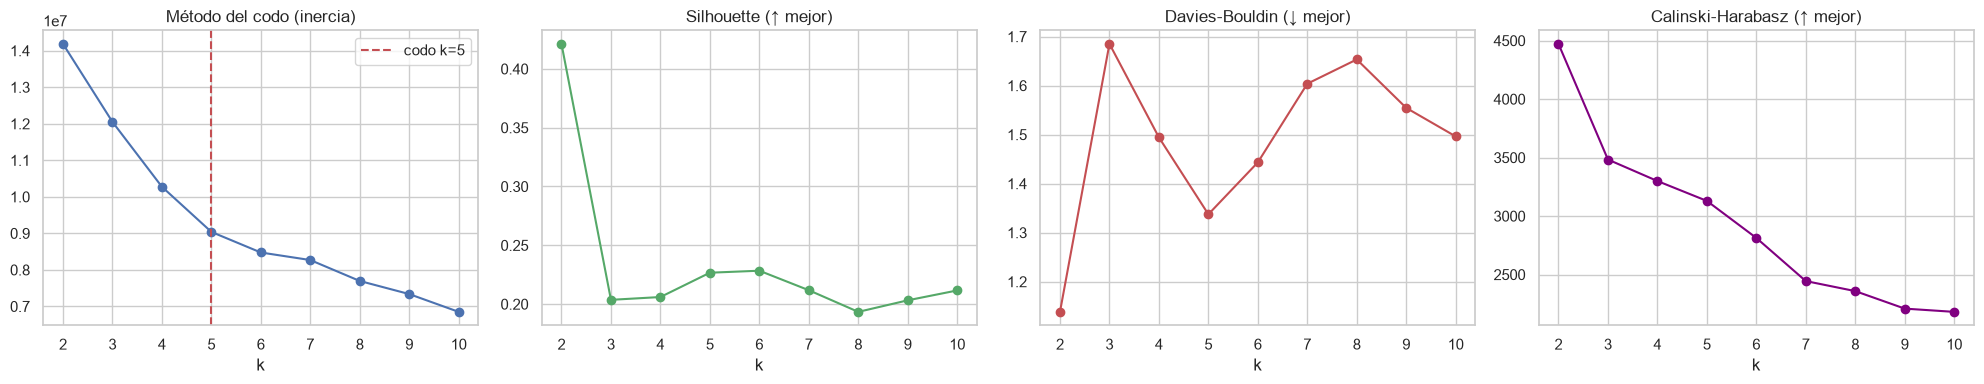

In [20]:
# Punto de codo por el método de la distancia máxima a la recta (Kneedle simplificado)
ks = np.array(list(rango_k)); inercias = busqueda_k["inercia"].values
x_n = (ks - ks.min()) / (ks.max() - ks.min()); y_n = (inercias - inercias.min()) / (inercias.max() - inercias.min())
k_codo = int(ks[np.argmax((1 - x_n) - y_n)])
k_silhouette = int(busqueda_k["silhouette"].idxmax())
print(f"k sugerido por el codo: {k_codo} | k con mayor silhouette: {k_silhouette}")

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].plot(ks, inercias, "o-"); axes[0].axvline(k_codo, ls="--", c="r", label=f"codo k={k_codo}")
axes[0].set_title("Método del codo (inercia)"); axes[0].legend()
axes[1].plot(ks, busqueda_k["silhouette"], "o-", c="g"); axes[1].set_title("Silhouette (↑ mejor)")
axes[2].plot(ks, busqueda_k["davies_bouldin"], "o-", c="r"); axes[2].set_title("Davies-Bouldin (↓ mejor)")
axes[3].plot(ks, busqueda_k["calinski_harabasz"], "o-", c="purple"); axes[3].set_title("Calinski-Harabasz (↑ mejor)")
for ax in axes: ax.set_xlabel("k"); ax.set_xticks(ks)
plt.tight_layout(); plt.show()

In [21]:
# Regla de decisión: entre los k "razonables" (3 a 8, interpretables para negocio),
# se elige el de mayor silhouette, desempatando con Davies-Bouldin.
candidatos = busqueda_k.loc[3:8]
K_FINAL = int(candidatos["silhouette"].idxmax())
print(f"k elegido: {K_FINAL}")

k elegido: 6


### Por qué se queda con 6 y no con 2

- **El máximo de silueta está en k = 2 (≈ 0,42).** Es una partición trivial que separa casi solo los **viajes de aeropuerto** del resto, porque la variable binaria `aeropuerto` provoca un salto muy marcado. La métrica es alta, pero el resultado no aporta nada: dos grupos no son una segmentación. Se descarta.
- **El codo** marca k = 5 y la curva de inercia se aplana a partir de k = 5-6.
- **Entre 3 y 8**, k = 5 y k = 6 están prácticamente empatados en silueta (≈ 0,227 frente a ≈ 0,228); k = 5 tiene algo mejor de Davies-Bouldin (1,337 frente a 1,443) y k = 6 separa además los viajes entre semana por franja horaria (mañana frente a tarde).
- Aplicando la regla que se fijó **antes** de mirar los segmentos (máxima silueta dentro del rango 3-8) la elección es **k = 6**. La alternativa k = 5 sería igual de defendible y se discute en las limitaciones.


## 7. El modelo que se lleva: MiniBatch K-Means

**En qué consiste.** K-Means asigna cada registro al centroide más cercano y recalcula los centroides como la media de los registros que se le han asignado, minimizando la inercia. **MiniBatch K-Means** hace exactamente lo mismo, pero actualiza los centroides con lotes pequeños aleatorios (aquí 8.192 filas), lo que recorta el tiempo y la memoria de forma drástica a costa de una pérdida mínima de calidad.

**Por qué se elige este y no otro:**

- Escala a millones de registros (complejidad lineal) y permite entrenarlo con el **100 % de los datos**.
- Sus centroides son interpretables: cada grupo se resume en un "viaje típico".
- Las variables ya están estandarizadas y transformadas con logaritmo, lo que acerca los grupos a la forma esférica que K-Means supone.


In [22]:
t0 = time.time()
modelo_kmeans = MiniBatchKMeans(n_clusters=K_FINAL, batch_size=8192, n_init=10,
                                max_iter=300, random_state=SEMILLA)
df["cluster_km"] = modelo_kmeans.fit_predict(X_std)
print(f"Entrenado sobre {len(X_std):,} registros en {time.time()-t0:.1f} s")
df["cluster_km"].value_counts(normalize=True).sort_index().rename("proporción").to_frame()

Entrenado sobre 2,265,576 registros en 16.2 s


,proporción
cluster_km,
0,0.236
1,0.099
2,0.211
3,0.221
4,0.100
5,0.133


## 8. Dos contrincantes para contrastar

### 8.1 Gaussian Mixture Model (GMM)

Modela los datos como una mezcla de *k* gaussianas multivariadas con **covarianza completa**, de modo que admite grupos **elípticos, de tamaños y orientaciones distintas**, y devuelve una probabilidad de pertenencia en lugar de una asignación seca. Se entrena con el mismo *k* para que la comparación sea justa.


In [23]:
idx_gmm = np.random.RandomState(SEMILLA + 1).choice(len(X_std), 300_000, replace=False)
t0 = time.time()
modelo_gmm = GaussianMixture(n_components=K_FINAL, covariance_type="full", n_init=2,
                             max_iter=300, random_state=SEMILLA)
modelo_gmm.fit(X_std[idx_gmm])
df["cluster_gmm"] = modelo_gmm.predict(X_std)
prob_max = modelo_gmm.predict_proba(X_eval).max(axis=1)
print(f"GMM entrenado en {time.time()-t0:.1f} s | convergió: {modelo_gmm.converged_}")
print(f"Probabilidad media de pertenencia al cluster asignado: {prob_max.mean():.3f}")
print(f"Puntos 'ambiguos' (prob. máx < 0,6): {(prob_max < 0.6).mean():.1%}")
df["cluster_gmm"].value_counts(normalize=True).sort_index().rename("proporción").to_frame()

GMM entrenado en 9.7 s | convergió: True
Probabilidad media de pertenencia al cluster asignado: 0.963
Puntos 'ambiguos' (prob. máx < 0,6): 2.3%


,proporción
cluster_gmm,
0,0.091
1,0.171
2,0.265
3,0.234
4,0.230
5,0.008


### 8.2 DBSCAN, sobre una muestra

Agrupa por **densidad**: no necesita que le digan cuántos grupos hay y marca como ruido (−1) los puntos aislados. Su coste en tiempo y memoria impide aplicarlo a los 2,2 millones de filas, así que corre sobre la muestra de evaluación de 30.000 puntos. El parámetro `eps` se fija con el **gráfico de k-distancias** (distancia al vecino *min_samples*-ésimo).


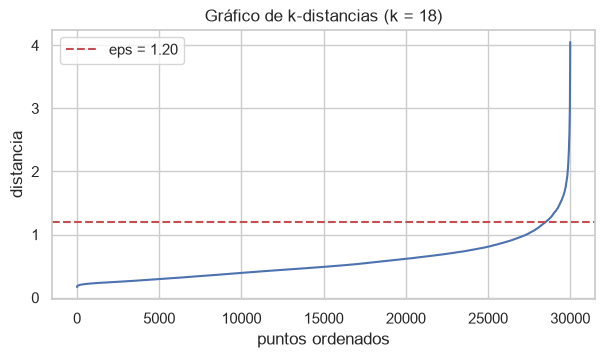

DBSCAN → clusters: 4 | ruido: 1.5%
 0    20254
 1     6871
 2     1909
 3      521
-1      445
Name: count, dtype: int64


In [24]:
MIN_SAMPLES = 2 * len(FEATURES)            # regla práctica: 2 × dimensiones
vecinos = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_eval)
dist_k = np.sort(vecinos.kneighbors(X_eval)[0][:, -1])
EPS = float(np.quantile(dist_k, 0.95))     # percentil 95 de la curva (zona del "codo")

plt.figure(figsize=(7, 3.5))
plt.plot(dist_k); plt.axhline(EPS, c="r", ls="--", label=f"eps = {EPS:.2f}")
plt.title(f"Gráfico de k-distancias (k = {MIN_SAMPLES})"); plt.ylabel("distancia"); plt.xlabel("puntos ordenados")
plt.legend(); plt.show()

etq_dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES, n_jobs=-1).fit_predict(X_eval)
n_cl = len(set(etq_dbscan)) - (1 if -1 in etq_dbscan else 0)
print(f"DBSCAN → clusters: {n_cl} | ruido: {(etq_dbscan == -1).mean():.1%}")
print(pd.Series(etq_dbscan).value_counts().head(10))

## 9. Las tres métricas obligatorias

| Métrica | Rango | Cómo se lee |
|---|---|---|
| **Silueta** | [−1, 1] | Cuanto más alto, mejor. Compara la distancia media al propio grupo con la del grupo vecino más cercano |
| **Davies-Bouldin** | [0, ∞) | Cuanto más bajo, mejor. Promedio del peor cociente dispersión/separación entre pares de grupos |
| **Calinski-Harabasz** | [0, ∞) | Cuanto más alto, mejor. Varianza entre grupos dividida por la varianza dentro de los grupos |

Las tres se calculan sobre la **misma muestra de 30.000 puntos**, para que la comparación sea legítima. En DBSCAN se excluye el ruido, lo que le favorece ligeramente. Además, para K-Means y GMM se añaden Davies-Bouldin y Calinski-Harabasz sobre una muestra mucho mayor (500.000), ya que su coste es lineal.


In [25]:
def metricas(Xm, etq):
    return {"silhouette": silhouette_score(Xm, etq),
            "davies_bouldin": davies_bouldin_score(Xm, etq),
            "calinski_harabasz": calinski_harabasz_score(Xm, etq)}

etq_km_eval = df["cluster_km"].to_numpy()[idx_eval]
etq_gmm_eval = df["cluster_gmm"].to_numpy()[idx_eval]
mask_db = etq_dbscan != -1

tabla = pd.DataFrame({
    f"MiniBatch K-Means (k={K_FINAL})": metricas(X_eval, etq_km_eval),
    f"GMM full (k={K_FINAL})": metricas(X_eval, etq_gmm_eval),
    f"DBSCAN ({n_cl} clusters, sin ruido)": metricas(X_eval[mask_db], etq_dbscan[mask_db]),
}).T
tabla["n_evaluado"] = [len(X_eval), len(X_eval), int(mask_db.sum())]
tabla

,silhouette,davies_bouldin,calinski_harabasz,n_evaluado
MiniBatch K-Means (k=6),0.230,1.454,"8,343.269",30000
GMM full (k=6),0.175,2.564,"5,453.270",30000
"DBSCAN (4 clusters, sin ruido)",0.219,1.809,"6,677.041",29555


In [26]:
# Métricas lineales sobre una muestra mayor (500.000) y estabilidad del silhouette con 5 muestras distintas
idx_grande = np.random.RandomState(7).choice(len(X_std), 500_000, replace=False)
for nombre, col in [("K-Means", "cluster_km"), ("GMM", "cluster_gmm")]:
    e = df[col].to_numpy()[idx_grande]
    print(f"{nombre:8s} | DB (500k) = {davies_bouldin_score(X_std[idx_grande], e):.3f} | "
          f"CH (500k) = {calinski_harabasz_score(X_std[idx_grande], e):,.0f}")

sil_rep = []
for s in range(5):
    i = np.random.RandomState(100 + s).choice(len(X_std), 20_000, replace=False)
    sil_rep.append(silhouette_score(X_std[i], df["cluster_km"].to_numpy()[i]))
print(f"\nSilhouette K-Means en 5 muestras de 20.000: media = {np.mean(sil_rep):.4f}, desv. = {np.std(sil_rep):.4f}")

K-Means  | DB (500k) = 1.453 | CH (500k) = 140,045


GMM      | DB (500k) = 2.606 | CH (500k) = 92,560



Silhouette K-Means en 5 muestras de 20.000: media = 0.2275, desv. = 0.0010


In [27]:
# Acuerdo entre K-Means y GMM (tabla de contingencia normalizada por fila)
from sklearn.metrics import adjusted_rand_score
print(f"Adjusted Rand Index K-Means vs GMM (muestra 30k): {adjusted_rand_score(etq_km_eval, etq_gmm_eval):.3f}")
pd.crosstab(df["cluster_km"], df["cluster_gmm"], normalize="index").round(2)

Adjusted Rand Index K-Means vs GMM (muestra 30k): 0.424


cluster_gmm,0,1,2,3,4,5
cluster_km,,,,,,
0,0.000,0.260,0.550,0.180,0.000,0.000
1,0.910,0.060,0.000,0.000,0.000,0.020
2,0.000,0.220,0.000,0.780,0.000,0.010
3,0.000,0.260,0.610,0.120,0.000,0.010
4,0.000,0.010,0.000,0.000,0.980,0.010
5,0.000,0.000,0.000,0.000,0.990,0.010


### Qué dicen los números

- **MiniBatch K-Means gana en las tres métricas**: silueta 0,230 (frente a 0,175 del GMM), Davies-Bouldin 1,454 (frente a 2,564) y Calinski-Harabasz 8.343 (frente a 5.453) sobre la misma muestra. En la muestra de 500.000 el resultado se mantiene: DB 1,453 frente a 2,606, y CH 140.045 frente a 92.560.
- **La silueta es estable.** En 5 muestras distintas de 20.000 registros la media es 0,2275 y la desviación 0,0010, lo que justifica usar una muestra en lugar de los 2,27 millones de puntos.
- **Una silueta de ≈ 0,23 es moderada.** Los grupos existen, pero **sus fronteras se solapan**. Es lo esperable en datos de comportamiento: un viaje de 2 millas y otro de 2,5 no se separan por un corte limpio.
- **El GMM** asigna con mucha confianza (probabilidad media de pertenencia 0,963, y solo un 2,3 % de puntos ambiguos con probabilidad máxima < 0,6), pero sus componentes se deforman para cubrir las variables binarias: **fusiona los dos grupos de fin de semana** de K-Means en uno solo y crea un componente diminuto (0,8 %) de casos atípicos. El acuerdo con K-Means es parcial (ARI 0,424); coinciden casi por completo en el grupo de **aeropuerto** y en el de **fin de semana**.
- **DBSCAN** (solo sobre 30.000 puntos) encuentra 4 regiones densas y un 1,5 % de ruido. Sus grupos tienen tamaños muy desiguales (68 %, 23 %, 6 % y 2 %) y siguen sobre todo la estructura de las variables binarias (entre semana / fin de semana / aeropuerto). Sirve para detectar atípicos, pero no escala al dataset completo y su resultado depende mucho de `eps`.

**Conclusión de la comparación:** se adopta **MiniBatch K-Means con k = 6** como modelo final, por sus mejores métricas, por su escalabilidad (entrena con los 2,27 millones de viajes en segundos) y por la interpretabilidad de sus centroides.


## 10. Dibujar los grupos


Varianza explicada por PC1 + PC2: 57.6% (43.4% + 14.1%)


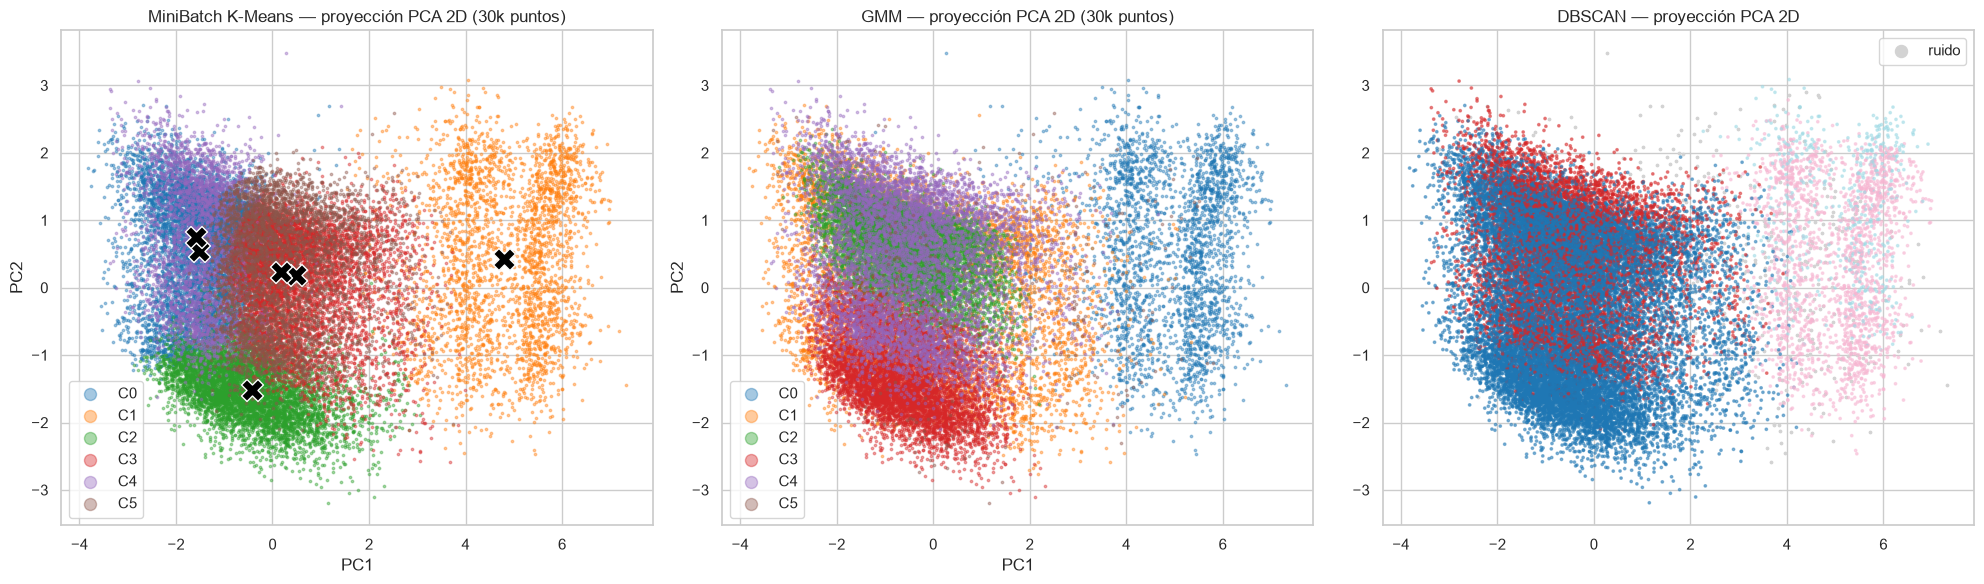

In [28]:
pca = PCA(n_components=2, random_state=SEMILLA).fit(X_std[idx_gmm])
Z = pca.transform(X_eval)
print(f"Varianza explicada por PC1 + PC2: {pca.explained_variance_ratio_.sum():.1%} "
      f"({pca.explained_variance_ratio_[0]:.1%} + {pca.explained_variance_ratio_[1]:.1%})")

paleta = sns.color_palette("tab10", K_FINAL)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, etq, titulo in [(axes[0], etq_km_eval, "MiniBatch K-Means"), (axes[1], etq_gmm_eval, "GMM")]:
    for c in range(K_FINAL):
        m = etq == c
        ax.scatter(Z[m, 0], Z[m, 1], s=3, alpha=.4, color=paleta[c], label=f"C{c}")
    ax.set_title(f"{titulo} — proyección PCA 2D (30k puntos)"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.legend(markerscale=5, loc="best")
# Centroides de K-Means proyectados
cent_pca = pca.transform(modelo_kmeans.cluster_centers_)
axes[0].scatter(cent_pca[:, 0], cent_pca[:, 1], marker="X", s=250, c="black", edgecolor="white")
# DBSCAN
colores_db = np.where(etq_dbscan == -1, -1, etq_dbscan)
axes[2].scatter(Z[etq_dbscan == -1, 0], Z[etq_dbscan == -1, 1], s=3, c="lightgrey", label="ruido")
axes[2].scatter(Z[mask_db, 0], Z[mask_db, 1], s=3, c=etq_dbscan[mask_db], cmap="tab20", alpha=.5)
axes[2].set_title("DBSCAN — proyección PCA 2D"); axes[2].legend(markerscale=5)
plt.tight_layout(); plt.show()

In [29]:
# Cargas (loadings) de los componentes: qué variables explican cada eje del PCA
pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"]).round(3)

,PC1,PC2
log_distancia,0.496,0.026
log_duracion,0.426,-0.176
velocidad_mph,0.371,0.244
log_tarifa,0.488,-0.067
pct_propina,-0.201,0.315
hora_sin,0.007,-0.501
hora_cos,0.032,0.698
fin_semana,-0.002,0.227
aeropuerto,0.393,0.125


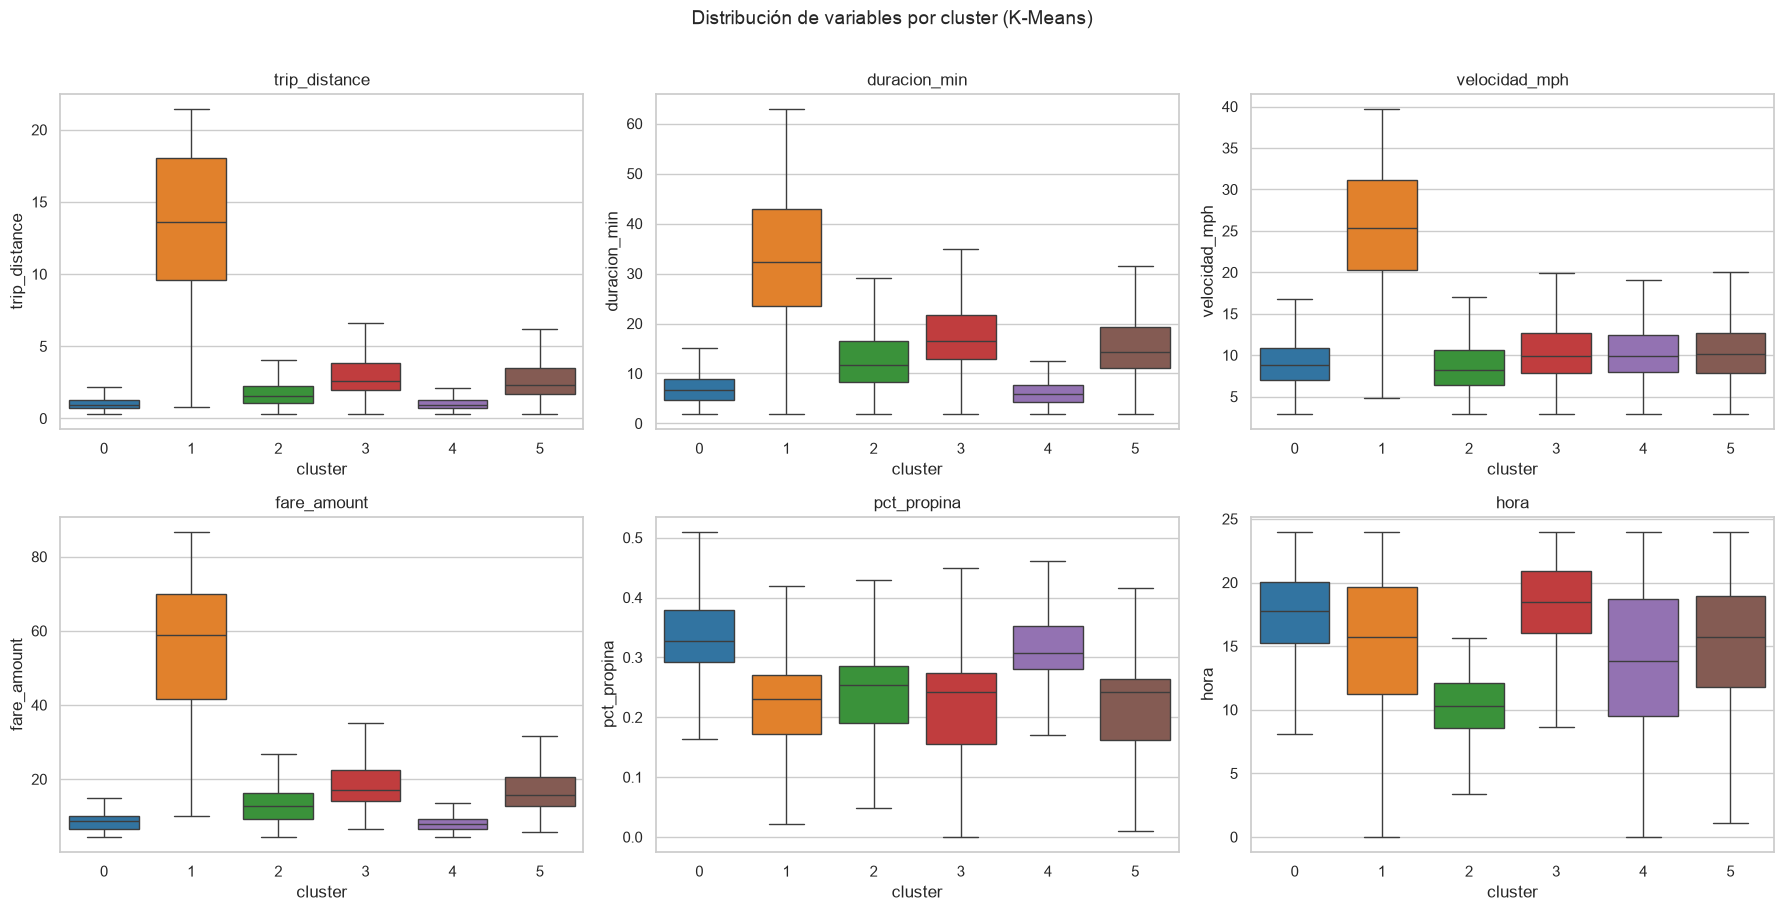

In [30]:
# Distribuciones de las variables originales por cluster (K-Means), sobre una muestra de 100k
muestra = df.sample(100_000, random_state=SEMILLA)
vars_orig = ["trip_distance", "duracion_min", "velocidad_mph", "fare_amount", "pct_propina", "hora"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, v in zip(axes.ravel(), vars_orig):
    sns.boxplot(data=muestra, x="cluster_km", y=v, hue="cluster_km", palette=paleta,
                legend=False, ax=ax, showfliers=False)
    ax.set_title(v); ax.set_xlabel("cluster")
plt.suptitle("Distribución de variables por cluster (K-Means)", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

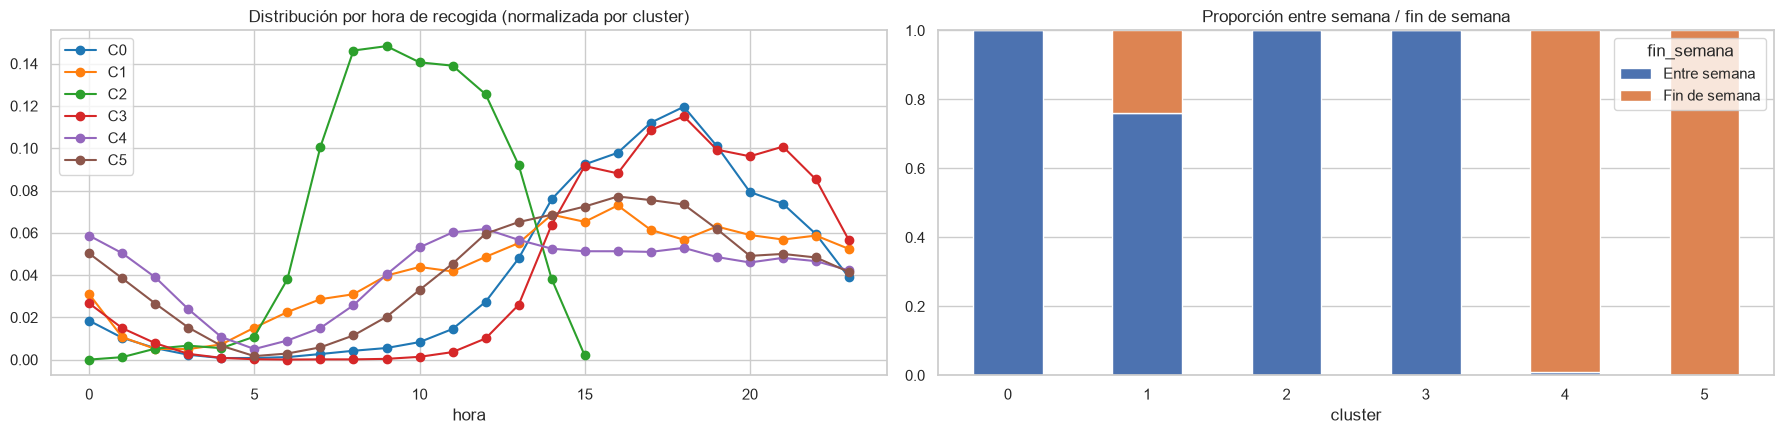

In [31]:
# Distribución horaria y por tipo de día de cada cluster
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
for c in range(K_FINAL):
    h = df.loc[df["cluster_km"] == c, "tpep_pickup_datetime"].dt.hour.value_counts(normalize=True).sort_index()
    axes[0].plot(h.index, h.values, "o-", color=paleta[c], label=f"C{c}")
axes[0].set_title("Distribución por hora de recogida (normalizada por cluster)"); axes[0].set_xlabel("hora"); axes[0].legend()
pd.crosstab(df["cluster_km"], df["fin_semana"].map({0: "Entre semana", 1: "Fin de semana"}),
            normalize="index").plot.bar(stacked=True, ax=axes[1], color=["#4C72B0", "#DD8452"])
axes[1].set_title("Proporción entre semana / fin de semana"); axes[1].set_xlabel("cluster"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## 11. Qué contiene cada grupo


In [32]:
perfil = df.groupby("cluster_km").agg(
    n_viajes=("trip_distance", "size"),
    distancia_mi=("trip_distance", "median"),
    duracion_min=("duracion_min", "median"),
    velocidad_mph=("velocidad_mph", "median"),
    tarifa_usd=("fare_amount", "median"),
    total_usd=("total_amount", "median"),
    pct_propina=("pct_propina", "median"),
    hora_mediana=("hora", "median"),
    pct_fin_semana=("fin_semana", "mean"),
    pct_aeropuerto=("aeropuerto", "mean"),
    pasajeros=("passenger_count", "mean"),
)
perfil["pct_viajes"] = 100 * perfil["n_viajes"] / perfil["n_viajes"].sum()
perfil["ingreso_total_pct"] = 100 * df.groupby("cluster_km")["total_amount"].sum() / df["total_amount"].sum()
# Franja horaria más frecuente
franjas = pd.cut(df["tpep_pickup_datetime"].dt.hour, [-1, 5, 9, 15, 19, 23],
                 labels=["Madrugada (0-5)", "Mañana pico (6-9)", "Mediodía (10-15)", "Tarde pico (16-19)", "Noche (20-23)"])
perfil["franja_dominante"] = pd.crosstab(df["cluster_km"], franjas).idxmax(axis=1)
perfil

,n_viajes,distancia_mi,duracion_min,velocidad_mph,tarifa_usd,total_usd,pct_propina,hora_mediana,pct_fin_semana,pct_aeropuerto,pasajeros,pct_viajes,ingreso_total_pct,franja_dominante
cluster_km,,,,,,,,,,,,,,
0,534328,0.970,6.767,8.772,8.600,16.320,0.327,17.750,0.000,0.001,1.299,23.585,14.009,Tarde pico (16-19)
1,223186,13.740,32.550,25.194,59.000,81.120,0.231,15.683,0.240,0.915,1.399,9.851,28.928,Mediodía (10-15)
2,478943,1.540,11.700,8.270,12.100,19.320,0.254,10.250,0.000,0.001,1.247,21.140,15.944,Mediodía (10-15)
3,500493,2.610,16.500,9.910,17.000,26.620,0.243,18.450,0.000,0.001,1.322,22.091,23.469,Tarde pico (16-19)
4,226322,0.950,5.967,9.933,7.900,14.600,0.308,13.817,0.990,0.001,1.402,9.990,5.303,Mediodía (10-15)
5,302304,2.320,14.300,10.022,15.600,23.340,0.242,15.683,1.000,0.001,1.434,13.343,12.348,Mediodía (10-15)


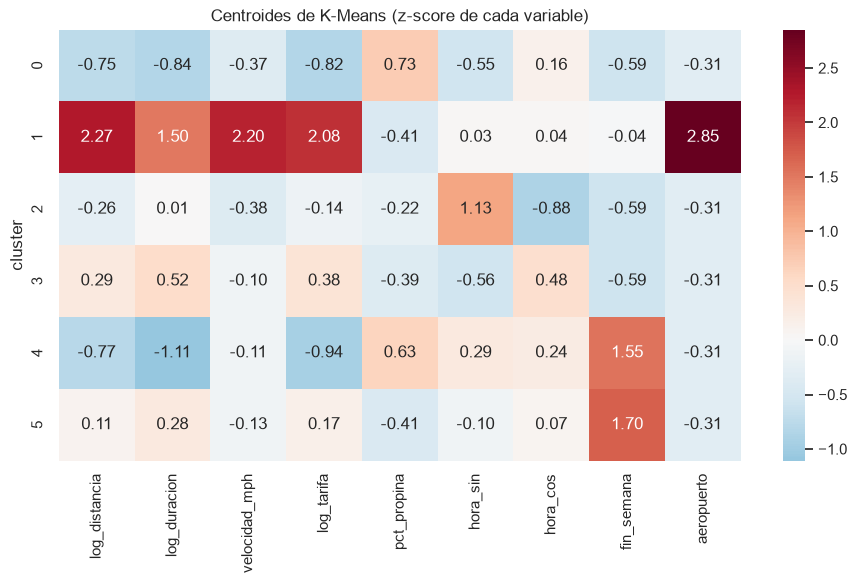

In [33]:
# Centroides en unidades estandarizadas (z-scores): cuánto se aleja cada cluster de la media global
centroides_z = pd.DataFrame(modelo_kmeans.cluster_centers_, columns=FEATURES)
plt.figure(figsize=(11, 0.6 * K_FINAL + 2))
sns.heatmap(centroides_z, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Centroides de K-Means (z-score de cada variable)"); plt.ylabel("cluster"); plt.show()

In [34]:
# Zonas de origen y destino más frecuentes por cluster (usa la tabla pública de zonas TLC, sin autenticación)
URL_ZONAS = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
RUTA_ZONAS = os.path.join("data", "taxi_zone_lookup.csv")
try:
    if not os.path.exists(RUTA_ZONAS):
        urllib.request.urlretrieve(URL_ZONAS, RUTA_ZONAS)
    zonas = pd.read_csv(RUTA_ZONAS).set_index("LocationID")
    nombre = lambda i: f"{zonas.loc[i, 'Zone']} ({zonas.loc[i, 'Borough']})" if i in zonas.index else str(i)
except Exception as e:
    print("No se pudo descargar la tabla de zonas:", e)
    nombre = str

filas = []
for c in range(K_FINAL):
    sub = df[df["cluster_km"] == c]
    top_pu = sub["PULocationID"].value_counts(normalize=True).head(3)
    top_do = sub["DOLocationID"].value_counts(normalize=True).head(3)
    filas.append({"cluster": c,
                  "top_origenes": " | ".join(f"{nombre(i)} {p:.0%}" for i, p in top_pu.items()),
                  "top_destinos": " | ".join(f"{nombre(i)} {p:.0%}" for i, p in top_do.items())})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(filas).set_index("cluster"))

,top_origenes,top_destinos
cluster,,
0,Upper East Side South (Manhattan) 7% | Upper East Side North (Manhattan) 6% | Midtown Center (Manhattan) 6%,Upper East Side North (Manhattan) 7% | Upper East Side South (Manhattan) 7% | Lincoln Square East (Manhattan) 4%
1,JFK Airport (Queens) 45% | LaGuardia Airport (Queens) 33% | East Elmhurst (Queens) 4%,JFK Airport (Queens) 8% | LaGuardia Airport (Queens) 5% | Times Sq/Theatre District (Manhattan) 4%
2,Upper East Side North (Manhattan) 8% | Upper East Side South (Manhattan) 7% | Penn Station/Madison Sq West (Manhattan) 5%,Midtown Center (Manhattan) 8% | Upper East Side South (Manhattan) 7% | Upper East Side North (Manhattan) 6%
3,Midtown Center (Manhattan) 7% | Midtown East (Manhattan) 5% | Times Sq/Theatre District (Manhattan) 5%,Upper East Side North (Manhattan) 5% | Upper West Side South (Manhattan) 4% | Upper West Side North (Manhattan) 3%
4,Upper East Side South (Manhattan) 5% | Upper East Side North (Manhattan) 5% | Lincoln Square East (Manhattan) 5%,Upper East Side North (Manhattan) 5% | Upper East Side South (Manhattan) 5% | Lincoln Square East (Manhattan) 4%
5,Penn Station/Madison Sq West (Manhattan) 5% | East Village (Manhattan) 4% | West Village (Manhattan) 4%,Upper East Side North (Manhattan) 4% | Lincoln Square East (Manhattan) 3% | Upper West Side South (Manhattan) 3%


### Los seis segmentos, uno a uno

Los números son medianas por grupo (ver las tablas anteriores). El identificador numérico de cada grupo es arbitrario.

| Grupo | Nombre propuesto | % viajes | % ingresos | Rasgos que lo definen |
|---|---|---|---|---|
| **C1** | ✈️ **Aeropuerto / larga distancia** | 9,9 % | **28,9 %** | 13,7 mi, 33 min, **25 mph**, tarifa ≈ 59 USD (total ≈ 81 USD), 92 % con recargo o tarifa de aeropuerto, peajes ≈ 4,9 USD de media; origen JFK (45 %) y LaGuardia (33 %); propina ≈ 23 % |
| **C3** | 🏠 **Regreso a casa entre semana (tarde-noche)** | 22,1 % | 23,5 % | 2,6 mi, 16,5 min, ≈ 10 mph; 75 % entre las 16 y las 23 h; origen Midtown/Times Square → destino Upper East/West Side (barrios residenciales) |
| **C2** | 🏢 **Desplazamientos de mañana/mediodía entre semana** | 21,1 % | 15,9 % | 1,5 mi, 11,7 min, **la velocidad más baja (≈ 8,3 mph)** → congestión; 97 % entre las 6 y las 15 h; destino principal Midtown Center (zona de oficinas) |
| **C0** | 🏙 **Cortos urbanos entre semana (tarde-noche)** | 23,6 % | 14,0 % | ≈ 1 mi, 7 min, tarifa ≈ 8,6 USD; **propina más alta (≈ 33 %)**, porque la propina sugerida pesa más sobre tarifas pequeñas; Upper East Side |
| **C5** | 🎉 **Ocio de fin de semana (trayectos medios)** | 13,3 % | 12,3 % | 2,3 mi, 14 min, 100 % fin de semana; origen East/West Village y Penn Station; 14 % de madrugada (0-5 h) |
| **C4** | 🚕 **Cortos de fin de semana** | 10,0 % | 5,3 % | ≈ 0,95 mi, 6 min, 99 % fin de semana, propina alta (≈ 31 %); 19 % de madrugada (vida nocturna) |

### Lectura desde el negocio

- **C1 (aeropuerto)** es el segmento más valioso: con menos del 10 % de los viajes genera cerca del **29 % de los ingresos**. Es la prioridad para la gestión de flota en terminales y para los acuerdos de tarifa plana.
- **C2** destapa el coste de la **congestión matutina**: viajes cortos pero lentos (≈ 8 mph). Candidato natural a tarifas dinámicas por hora o a rutas alternativas.
- **C0 y C4** son viajes muy cortos con propinas porcentuales altas, pero con poco ingreso absoluto: buenos candidatos para incentivos de alta rotación.
- **C3 y C5** son trayectos medios asociados al ocio y a la vuelta a casa: la demanda se concentra en tarde/noche y fines de semana, útil para planificar turnos de conductores.
- Las variables que más mandan en la segmentación son la **distancia y la tarifa** (eje PC1 del PCA), la **hora del día** (PC2) y el **tipo de día** (entre semana frente a fin de semana). El PC1+y PC2 explican el 57,6 % de la varianza (43,4 % + 14,1 %).


## 12. Límites, riesgos y veredicto

### Límites del trabajo

1. **Sesgo de selección**: solo se usan los pagos con tarjeta (≈ 78 % de los viajes) porque son los únicos con propina fiable. Los viajes en efectivo y los *flex fare* (`payment_type = 0`) quedan fuera, y podrían tener perfiles distintos (turistas, usuarios con menor poder adquisitivo).
2. **Un único mes (enero de 2024)**: hay estacionalidad (invierno, festividad de año nuevo). Los segmentos podrían cambiar en verano.
3. **Variables binarias dentro de K-Means**: `fin_semana` y `aeropuerto` generan "saltos" que dominan buena parte de la partición, y de ahí que aparezcan parejas de grupos entre semana / fin de semana. Alternativas: ponderar menos esas variables o recurrir a K-Prototypes.
4. **Redundancia**: distancia, duración y tarifa están muy correlacionadas, lo que da más peso implícito a "la longitud del viaje". Un PCA previo o eliminar una de ellas desplazaría ligeramente los grupos.
5. **La geografía queda fuera** del modelo (265 zonas categóricas) para no disparar la dimensionalidad; solo se usa para interpretar.
6. **Silueta moderada (≈ 0,23)**: los segmentos se solapan y hay viajes de frontera que encajarían con dos grupos.
7. **k = 5 frente a k = 6** están prácticamente empatados; la elección de 6 se apoya en una regla fijada de antemano y en la interpretabilidad.

### Errores posibles

- Las **métricas se calcularon sobre muestras** (30.000 para la silueta). Su variabilidad medida es mínima (desviación ≈ 0,001), pero no son el valor exacto poblacional.
- La **winsorización** y las reglas de limpieza (1-80 mph, tarifa ≥ 3 USD...) son decisiones del analista: otros umbrales mueven los extremos de los grupos.
- **MiniBatch K-Means es aproximado** y depende de la inicialización; se compensó con `n_init = 10` y semilla fija. Con otra versión de scikit-learn (por ejemplo, en Colab) la numeración de los grupos o alguna cifra puede variar ligeramente: la interpretación debe hacerse sobre las tablas de perfil que genera cada ejecución.
- **DBSCAN se evaluó sin los puntos de ruido**, lo que mejora artificialmente sus métricas; además solo corrió sobre una muestra.
- Las métricas internas miden **geometría, no utilidad de negocio**: un agrupamiento con mejor silueta (k = 2) puede ser mucho menos útil.

### Veredicto

- Se segmentaron **2,27 millones de viajes reales** de taxi de Nueva York sin usar ninguna etiqueta ni variable objetivo, después de limpiar nulos estructurales, valores imposibles y extremos, y de estandarizar 9 variables.
- El número de grupos se fijó con **codo + silueta** (apoyados en Davies-Bouldin y Calinski-Harabasz) y resultó ser **k = 6**.
- **MiniBatch K-Means** superó a **GMM** y a **DBSCAN** en las tres métricas obligatorias (silueta 0,230, Davies-Bouldin 1,454 y Calinski-Harabasz 140.045 en la muestra de 500.000) y fue el único capaz de entrenar con todos los datos en segundos.
- Los seis segmentos son **interpretables y accionables**: aeropuerto (alto valor), regreso a casa, desplazamientos matutinos congestionados, cortos urbanos, ocio de fin de semana y cortos de fin de semana.
- **Continuación posible**: incorporar más meses, meter la geografía (embeddings de zonas o coordenadas de centroides), probar K-Prototypes para variables mixtas y comprobar la estabilidad de los grupos con *bootstrap*.
